# 03 — Resultados

Resume los resultados de cada pieza del pipeline, para los dos servicios que lee la cooperativa: **agua** (medidores de rodillos en el piso, con la fracción de m³ en rojo) y **energía** (rodillos y LCD de 7 segmentos, en pared o pilar). Cada sección explica qué hace la pieza, cómo se evaluó y qué dicen los números, primero para agua y después para energía.

| Pieza | Qué resuelve | Agua | Energía |
|---|---|---|---|
| 1. Segmentación del visor | Dónde está el visor en la foto | YOLOv8n-seg (B) | YOLOv8n-seg con visores de energía |
| 2. Rectificación | Enderezar el visor antes de leerlo | rectángulo rotado mínimo | igual |
| 3. Detección de dígitos | Qué dígitos hay y en qué orden | `digits_yolov8n` | `digits_mix_energia_yolov8n` (E3) |
| 4. Orientación | Si el visor quedó al revés | se prueba el giro de 180° | sin giro (siempre derechos) |
| 5. Formato del medidor | Dónde va el punto entre m³ y fracción | `meter_layout_mnv3s` | `meter_layout_agua_energia` |

Después vienen la lectura de punta a punta (sección 6), el pipeline paso a paso sobre fotos reales (sección 7) y las conclusiones.

- No entrena nada: usa los pesos versionados en `models/`, las métricas de `experiments/` y las fotos de `data/ceml/` (agua) y `data/ceml_energia/` (energía).
- Algunas comparaciones (orientación, detectores de energía, segmentación sobre la muestra de energía) se calculan acá mismo sobre las fotos. Corre en CPU en unos minutos, con las dependencias de `requirements.txt`.
- **Fotos de prueba:** agua, las 323 fotos CEML verificadas y legibles; energía, una muestra aparte de 201 fotos verificadas (`muestra=si`), de medidores que no se usaron para entrenar.
- El detalle de cada experimento está en [experiments/README.md](../experiments/README.md) y el motivo de cada decisión en [docs/decisiones.md](../docs/decisiones.md).

In [1]:
import csv
import json
import os
import sys
import tempfile
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import ultralytics  # noqa: F401  (antes que torch: configura los hilos de OpenMP)
import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
import pandas as pd

from evaluate_pipeline import load_ground_truth, score  # mismas métricas que experiments/
from meter_reader.pipeline import CROP_PAD, MIN_MODEL_PROB, load_models, read_meter
from meter_reader.rectify import bbox_crop, rectify

EXP = ROOT / "experiments"
WATER, ENERGY = ROOT / "data/ceml", ROOT / "data/ceml_energia"
METRICS = ["exacta", "m3_exactos", "cer", "sin_lectura"]


def load(path):
    return json.loads((EXP / path).read_text(encoding="utf-8"))


def load_oof(name):
    """Predicción out-of-fold del clasificador de formato: archivo → (formato, probabilidad)."""
    with (EXP / name / "oof.csv").open(newline="", encoding="utf-8") as f:
        return {r["file"]: (r["predicho"], float(r["probabilidad"])) for r in csv.DictReader(f)}


def yolo_polygon(label, width, height):
    """Polígono del visor (primera línea de una etiqueta YOLO-seg) en píxeles."""
    values = list(map(float, label.read_text().split()[1:]))
    return np.array(values, dtype=np.float32).reshape(-1, 2) * [width, height]


def segment_all(truth, images_dir, segment):
    """Segmenta cada foto una sola vez: todas las variantes leen sobre el mismo visor."""
    return {t["file"]: segment(cv2.imread(str(images_dir / t["file"]))) for t in truth}


def read_all(truth, images_dir, polygons, detect, oof, allow_flip=True):
    """Lee todas las fotos con el visor ya segmentado. Devuelve archivo → (lectura, confianza) o None."""
    predictions = {}
    for t in truth:
        image = cv2.imread(str(images_dir / t["file"]))
        label = oof.get(t["file"], ("", 0.0))
        result = read_meter(image, lambda _img, p=polygons[t["file"]]: p, detect,
                            lambda _input, label=label: label, allow_flip=allow_flip)
        reading = result.reading
        predictions[t["file"]] = (reading.formatted, reading.confidence) if reading.text else None
    return predictions


def plot_training(experiments, column, title, ylabel):
    """Curva de validación por época a partir de experiments/<nombre>/results.csv (Ultralytics)."""
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for label, name in experiments.items():
        log = pd.read_csv(EXP / name / "results.csv")
        log.columns = log.columns.str.strip()
        ax.plot(log["epoch"], log[column], label=label)
    ax.set(title=title, xlabel="época", ylabel=ylabel)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


set_matplotlib_formats("jpeg")  # figuras livianas: muchas son fotos
pd.set_option("display.precision", 3)
water_truth = load_ground_truth(WATER / "readings.csv")
energy_truth = load_ground_truth(ENERGY / "readings.csv")
energy_sheet = pd.read_csv(ENERGY / "readings.csv", dtype=str).fillna("")
print(f"Fotos de prueba: agua {len(water_truth)}, energía {len(energy_truth)}")

Fotos de prueba: agua 323, energía 201


## 1. Segmentación del visor

**Qué hace.** Encuentra el visor (la ventana con los números) dentro de la foto completa. Es segmentación de instancia: además de la caja, devuelve el contorno del visor como polígono, y ese polígono es lo que permite enderezarlo en la pieza siguiente. El visor ocupa en mediana menos del 2 % de la foto (ver `01_eda.ipynb`), por eso se lo busca primero y los dígitos se leen después sobre el recorte.

**Cómo se evalúa.** Con las métricas de máscara de Ultralytics:

- **mAP50**: precisión promedio cuando la máscara predicha se superpone al menos un 50 % con la real (IoU ≥ 0,5). Mide si el visor se encontró.
- **mAP50-95**: el promedio entre IoU 0,5 y 0,95. Exige además que el contorno sea preciso.
- **Recall**: qué parte de los visores reales se encontró. Es la métrica que más importa para el pipeline, porque un visor no detectado es una lectura perdida.

### Agua

Se evalúa en el test de Toloka (el dominio de entrenamiento) y en las 324 fotos de campo CEML de agua (el dominio real, que el modelo nunca vio en entrenamiento).

- **A**: solo Toloka.
- **B**: Toloka + water-meter-dataset (yfzw4), con el visor derivado de las cajas de los dígitos. Es el modelo de la entrega de agua.
- **C**: B entrenado a 1024 px.
- **D**: B con 587 fotos de energía de más en train (el segmentador de energía). Se incluye para ver que agregar energía no empeora agua.

In [2]:
seg = {"A: Toloka, 640 px": "toloka_yolov8n_seg",
       "B: Toloka + yfzw4, 640 px": "toloka_yfzw4_yolov8n_seg",
       "C: Toloka + yfzw4, 1024 px": "toloka_yfzw4_yolov8n_seg_1024",
       "D: B + energía, 640 px": "toloka_yfzw4_energia_yolov8n_seg"}
rows = []
for name, exp in seg.items():
    e = load(f"{exp}/eval.json")
    rows.append({"configuración": name,
                 "Toloka mAP50-95": e["toloka_test"]["mask_map50_95"],
                 "CEML mAP50": e["ceml"]["mask_map50"],
                 "CEML mAP50-95": e["ceml"]["mask_map50_95"],
                 "CEML recall": e["ceml"]["mask_recall"],
                 "CPU (ms)": e["cpu_latency_ms"]})
pd.DataFrame(rows).set_index("configuración")

,Toloka mAP50-95,CEML mAP50,CEML mAP50-95,CEML recall,CPU (ms)
configuración,,,,,
"A: Toloka, 640 px",0.877,0.858,0.429,0.867,24.1
"B: Toloka + yfzw4, 640 px",0.847,0.937,0.434,0.910,24.2
"C: Toloka + yfzw4, 1024 px",0.901,0.940,0.401,0.931,51.4
"D: B + energía, 640 px",0.851,0.941,0.404,0.921,83.0


**Curvas de entrenamiento.** mAP50-95 de máscara en validación (Toloka) por época. B y D usan los mismos hiperparámetros: el entrenamiento converge igual con o sin los visores de energía.

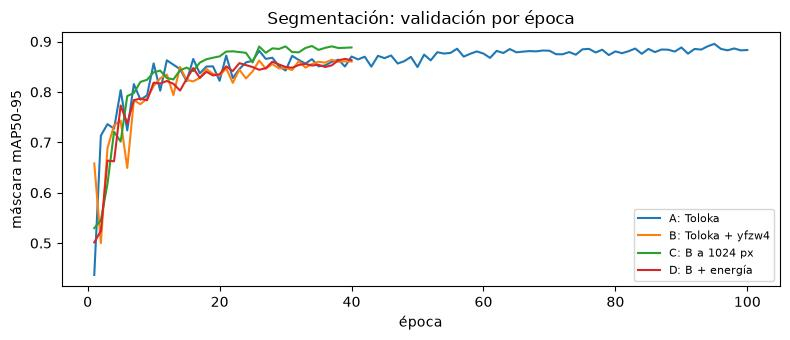

In [3]:
plot_training({"A: Toloka": "toloka_yolov8n_seg", "B: Toloka + yfzw4": "toloka_yfzw4_yolov8n_seg",
               "C: B a 1024 px": "toloka_yfzw4_yolov8n_seg_1024", "D: B + energía": "toloka_yfzw4_energia_yolov8n_seg"},
              "metrics/mAP50-95(M)", "Segmentación: validación por época", "máscara mAP50-95")

- **B frente a A**: sumar water-meter-dataset sube el recall en CEML de 0,867 a 0,910 y el mAP50 de 0,858 a 0,937. Más variedad de medidores ayuda más que la precisión del contorno de Toloka.
- **C frente a B**: 1024 px encuentra algún visor más (recall 0,931), pero duplica la latencia y no mejora el contorno. Se queda B.
- **D frente a B**: agregar energía no empeora agua (recall en CEML 0,921 contra 0,910). Igual, la app sigue usando B para agua, que es el modelo evaluado en la entrega. La latencia de D se midió en la CPU de Kaggle (como la tabla siguiente), no en la misma máquina que A, B y C.
- El mAP50-95 en CEML es bajo para todos (≈ 0,4) porque los polígonos de CEML y los de Toloka siguen criterios de borde distintos; el mAP50, que solo pide encontrar el visor, está por encima de 0,9.

**Dice e IoU por foto.** Las métricas de superposición de máscaras que se vieron en clase: IoU = |A ∩ B| / |A ∪ B| y Dice = 2 |A ∩ B| / (|A| + |B|), entre el visor que usa el pipeline (la instancia de mayor confianza) y el polígono revisado. Se promedian por foto, y una foto sin visor predicho cuenta como 0 (`scripts/evaluate_seg_dice.py`, resultados en `experiments/<modelo>/dice.json`). Se calculan sobre las 324 fotos de agua y las 201 de la muestra de energía.

,agua Dice,agua IoU,agua sin visor,energía Dice,energía IoU,energía sin visor
configuración,,,,,,
"A: Toloka, 640 px",0.786,0.716,0.111,0.433,0.377,0.468
"B: Toloka + yfzw4, 640 px",0.765,0.661,0.080,0.621,0.533,0.229
"C: Toloka + yfzw4, 1024 px",0.763,0.657,0.077,0.492,0.420,0.388
"D: B + energía, 640 px",0.760,0.653,0.071,0.951,0.912,0.000


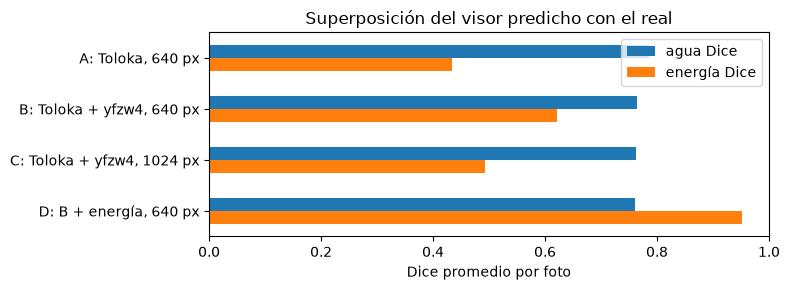

In [4]:
rows = []
for name, exp in seg.items():
    d = load(f"{exp}/dice.json")
    rows.append({"configuración": name,
                 "agua Dice": d["ceml_agua"]["dice"], "agua IoU": d["ceml_agua"]["iou"],
                 "agua sin visor": d["ceml_agua"]["sin_visor"],
                 "energía Dice": d["ceml_energia_muestra"]["dice"], "energía IoU": d["ceml_energia_muestra"]["iou"],
                 "energía sin visor": d["ceml_energia_muestra"]["sin_visor"]})
dice_table = pd.DataFrame(rows).set_index("configuración")
display(dice_table)
ax = dice_table[["agua Dice", "energía Dice"]].plot.barh(figsize=(8, 3), xlim=(0, 1))
ax.invert_yaxis()
ax.set(xlabel="Dice promedio por foto", ylabel="", title="Superposición del visor predicho con el real")
plt.tight_layout()
plt.show()

- **En agua, A tiene el mayor Dice** (0,786 contra 0,765 de B) aunque deja más fotos sin visor (11,1 % contra 8,0 %): su contorno se parece más al polígono revisado de CEML, que sigue el marco del visor como los de Toloka. B, con el visor derivado de los dígitos, encuentra más visores pero con un contorno algo más holgado. Para el pipeline pesa más encontrar el visor (una foto sin visor es una lectura perdida), y el rectificado agrega igual un margen del 5 %, por eso se eligió B.
- **En energía** los segmentadores de agua dejan sin visor entre el 23 % y el 47 % de las fotos; con los visores de energía en train (D), el Dice sube a 0,951 y no queda ninguna foto sin visor.
- Dice e IoU ordenan igual a los modelos (Dice es una transformación monótona de IoU para cada foto); Dice da valores más altos.

**YOLOv8n-seg contra Mask R-CNN** (mismos datos que B). Ultralytics y torchvision no calculan el mAP igual, así que los dos se comparan con pycocotools (`scripts/evaluate_seg_coco.py`). La latencia de esta tabla se midió en la misma máquina de Kaggle para los dos.

In [5]:
rows = []
for name, exp in {"YOLOv8n-seg (B)": "toloka_yfzw4_yolov8n_seg", "Mask R-CNN R50-FPN": "toloka_yfzw4_maskrcnn"}.items():
    e = load(f"{exp}/eval_coco.json")
    rows.append({"arquitectura": name,
                 "Toloka máscara AP50-95": e["toloka_test"]["mask_ap50_95"],
                 "CEML máscara AP50": e["ceml"]["mask_ap50"],
                 "CEML máscara AP50-95": e["ceml"]["mask_ap50_95"],
                 "CEML caja AP50": e["ceml"]["box_ap50"],
                 "CPU (ms)": e["cpu_latency_ms"]})
pd.DataFrame(rows).set_index("arquitectura")

,Toloka máscara AP50-95,CEML máscara AP50,CEML máscara AP50-95,CEML caja AP50,CPU (ms)
arquitectura,,,,,
YOLOv8n-seg (B),0.847,0.908,0.359,0.948,85.3
Mask R-CNN R50-FPN,0.843,0.864,0.262,0.960,1771.1


Empatan en Toloka, pero en las fotos de campo YOLOv8n-seg encuentra mejor el visor y es unas 20 veces más rápido en CPU, que es donde corre la app. Se elige YOLOv8n-seg.

### Energía

Los medidores de energía no se parecen a los de agua: hay rodillos con marcos de otras marcas y pantallas LCD, y no había ningún visor de energía en los datos públicos. Los visores de las 788 fotos de energía se etiquetaron en Roboflow (SAM 3 con revisión manual) y 587 se sumaron a train (todas las de medidores fuera de la muestra de prueba).

Se compara B (solo agua) con el segmentador de energía sobre las 201 fotos de la muestra, que ninguno de los dos vio. La celda arma un conjunto de evaluación con las fotos de la muestra y sus polígonos revisados y lo evalúa con Ultralytics (tarda un minuto en CPU).

In [6]:
import logging

from ultralytics import YOLO
from ultralytics.utils import LOGGER

LOGGER.setLevel(logging.WARNING)  # sin la barra de progreso de la evaluación
sample_files = energy_sheet.loc[energy_sheet["muestra"] == "si", "file"].tolist()
sample_dir = Path(tempfile.mkdtemp()) / "muestra_energia"
for sub in ("images", "labels"):
    (sample_dir / sub).mkdir(parents=True)
for file in sample_files:
    (sample_dir / "images" / file).symlink_to(ENERGY / "images" / file)
    (sample_dir / "labels" / f"{Path(file).stem}.txt").symlink_to(ENERGY / "labels" / f"{Path(file).stem}.txt")
sample_yaml = sample_dir / "data.yaml"
sample_yaml.write_text(f"path: {sample_dir}\ntrain: images\nval: images\nnames: {{0: 'display'}}\n")

rows = []
for name, weights in {"B (solo agua)": "toloka_yfzw4_yolov8n_seg",
                      "D (con energía)": "toloka_yfzw4_energia_yolov8n_seg"}.items():
    res = YOLO(f"models/{weights}.pt").val(data=str(sample_yaml), imgsz=640, batch=8, device="cpu",
                                           plots=False, verbose=False)
    rows.append({"segmentador": name, "máscara mAP50": res.seg.map50, "máscara mAP50-95": res.seg.map,
                 "recall": res.seg.mr})
LOGGER.setLevel(logging.INFO)
pd.DataFrame(rows).set_index("segmentador")

,máscara mAP50,máscara mAP50-95,recall
segmentador,,,
B (solo agua),0.774,0.325,0.729
D (con energía),0.995,0.855,0.995


Abajo, fotos de la muestra donde el segmentador de agua (B, rojo) no encuentra el visor o lo encuentra con un contorno pobre (IoU menor a 0,5 con el polígono revisado), y lo que encuentra el de energía (D, verde).

Fotos de la muestra donde B no encuentra el visor (IoU < 0,5): 66 de 201


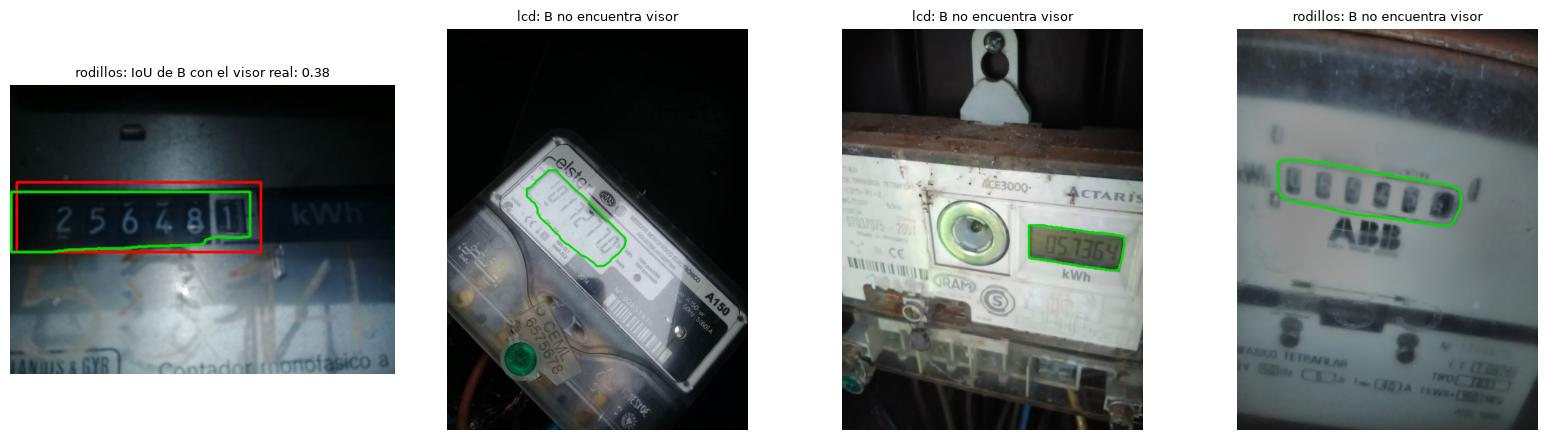

In [7]:
b_segment, _ = load_models("models/toloka_yfzw4_yolov8n_seg.pt", "models/digits_yolov8n.pt", device="cpu")
d_segment, _ = load_models("models/toloka_yfzw4_energia_yolov8n_seg.pt", "models/digits_yolov8n.pt", device="cpu")


def iou(p1, p2, shape):
    masks = [np.zeros(shape[:2], np.uint8) for _ in range(2)]
    for mask, poly in zip(masks, (p1, p2)):
        if poly is not None and len(poly) >= 3:
            cv2.fillPoly(mask, [poly.astype(np.int32)], 1)
    union = (masks[0] | masks[1]).sum()
    return (masks[0] & masks[1]).sum() / union if union else 0.0


failures = []
for file in sample_files:
    image = cv2.imread(str(ENERGY / "images" / file))
    truth_poly = yolo_polygon(ENERGY / "labels" / f"{Path(file).stem}.txt", image.shape[1], image.shape[0])
    b_poly = b_segment(image)
    overlap = iou(b_poly, truth_poly, image.shape)
    if overlap < 0.5:
        failures.append((file, image, b_poly, d_segment(image), overlap))
print(f"Fotos de la muestra donde B no encuentra el visor (IoU < 0,5): {len(failures)} de {len(sample_files)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (file, image, b_poly, d_poly, overlap) in zip(axes, failures[::max(1, len(failures) // 4)]):
    overlay = image.copy()
    width = max(3, image.shape[1] // 150)
    for poly, color in ((b_poly, (0, 0, 255)), (d_poly, (0, 220, 0))):
        if poly is not None and len(poly) >= 3:
            cv2.polylines(overlay, [poly.astype(np.int32)], True, color, width)
    ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    found = "B no encuentra visor" if b_poly is None else f"IoU de B con el visor real: {overlap:.2f}"
    ax.set_title(f"{energy_sheet.set_index('file').loc[file, 'tipo']}: {found}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

El segmentador de agua encuentra solo el 73 % de los visores de energía; con los visores de energía en train, los encuentra prácticamente todos y con un contorno mucho más preciso (mAP50-95 de 0,33 a 0,86). En la lectura de punta a punta esto se ve en las fotos sin lectura, que bajaron de 22,9 % a 0 %.

## 2. Rectificación

**Qué hace.** Endereza el visor antes de leerlo (`src/meter_reader/rectify.py`). Al polígono de la segmentación se le ajusta el rectángulo rotado de área mínima, se elige su lado largo como eje horizontal (los dígitos van a lo largo del visor) y una transformación afín lo lleva a un recorte horizontal, con un 5 % de margen. Es igual para los dos servicios.

**La alternativa** es recortar la caja alineada a los ejes que contiene al polígono, sin girar. Con un visor inclinado o vertical, ese recorte trae mucho fondo y los dígitos llegan torcidos al detector, que se entrenó con visores horizontales. Comparar los dos recortes es el **experimento principal** del trabajo (configuraciones A y C de la sección 6).

Abajo, un medidor de agua y uno de energía con el visor inclinado: la foto con el polígono, el recorte por caja y el visor rectificado.

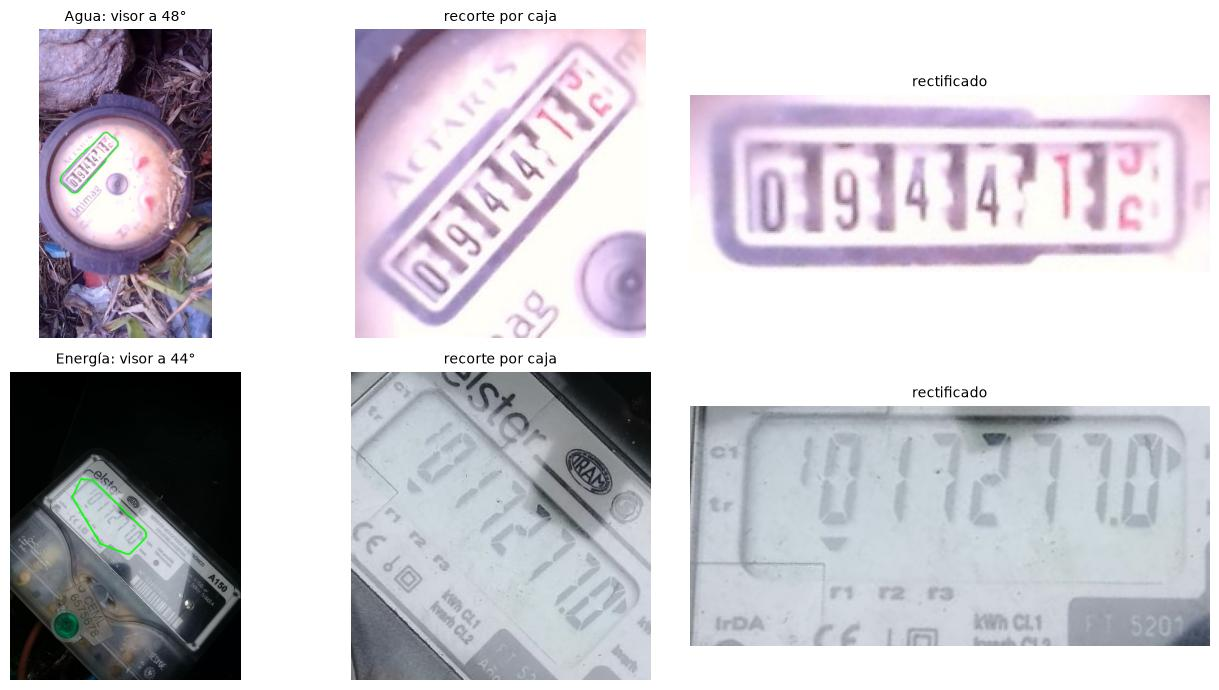

In [8]:
def tilt(polygon):
    """Inclinación del lado largo del rectángulo mínimo respecto de la horizontal, en grados (0-90)."""
    (_, _), (w, h), angle = cv2.minAreaRect(polygon.astype(np.float32))
    angle = (angle + (90 if w < h else 0)) % 180
    return min(angle, 180 - angle)


def most_tilted(sheet_files, root):
    """Foto con el visor más cercano a 45°: la que más muestra la diferencia entre los dos recortes."""
    best = None
    for file in sheet_files:
        label = root / "labels" / f"{Path(file).stem}.txt"
        if not label.exists():
            continue
        image = cv2.imread(str(root / "images" / file))
        polygon = yolo_polygon(label, image.shape[1], image.shape[0])
        score_ = abs(tilt(polygon) - 45)
        if best is None or score_ < best[0]:
            best = (score_, file, image, polygon)
    return best[1:]


examples = {"Agua": most_tilted([t["file"] for t in water_truth], WATER),
            "Energía": most_tilted(sample_files, ENERGY)}
fig, grid = plt.subplots(2, 3, figsize=(13, 7), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for (service, (file, image, polygon)), axes in zip(examples.items(), grid):
    overlay = image.copy()
    cv2.polylines(overlay, [polygon.astype(np.int32)], True, (0, 255, 0), max(3, image.shape[1] // 150))
    panels = [(overlay, f"{service}: visor a {tilt(polygon):.0f}°"),
              (bbox_crop(image, polygon, pad=CROP_PAD), "recorte por caja"),
              (rectify(image, polygon, pad=CROP_PAD)[0], "rectificado")]
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.axis("off")
plt.tight_layout()

El rectificado no decide si el visor quedó derecho o al revés: el lado largo puede quedar con los números hacia arriba o hacia abajo. Eso lo resuelve la pieza de orientación (sección 4).

## 3. Detección de dígitos

**Qué hace.** Un detector YOLO con una clase por dígito (0–9) busca los dígitos sobre el visor rectificado. La lectura se arma ordenando las detecciones de izquierda a derecha y quedándose con la de mayor confianza cuando dos cajas caen en la misma posición (`src/meter_reader/reading.py`). La confianza de la lectura es la del dígito menos seguro, y la app la usa para mandar a revisión las lecturas dudosas.

Se entrena sin espejado horizontal (`fliplr=0`): un 2 espejado se parece a un 5.

### Agua

Test de water-meter-dataset sobre el visor rectificado (656 recortes). YOLOv8n contra YOLO11n, con los mismos datos e hiperparámetros.

,map50,map50_95,precision,recall
modelo,,,,
digits_yolov8n,0.983,0.687,0.962,0.961
digits_yolo11n,0.984,0.694,0.968,0.955


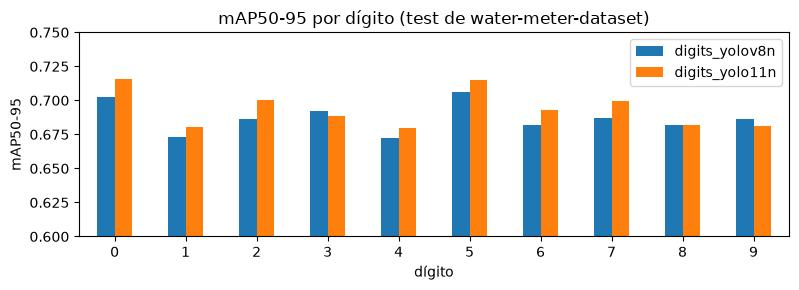

In [9]:
rows, per_class = [], {}
for name in ["digits_yolov8n", "digits_yolo11n"]:
    e = load(f"{name}/eval.json")
    rows.append({"modelo": name, **e["test"]})
    per_class[name] = e["map50_95_por_clase"]
display(pd.DataFrame(rows).set_index("modelo"))

ax = pd.DataFrame(per_class).plot.bar(figsize=(8, 3), ylim=(0.6, 0.75), rot=0)
ax.set_xlabel("dígito")
ax.set_ylabel("mAP50-95")
ax.set_title("mAP50-95 por dígito (test de water-meter-dataset)")
plt.tight_layout()

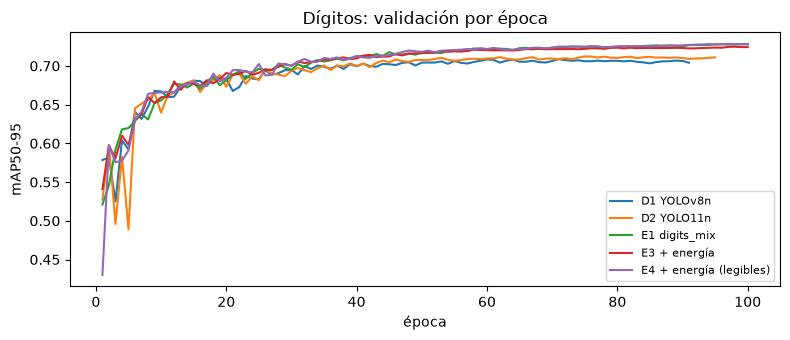

In [10]:
plot_training({"D1 YOLOv8n": "digits_yolov8n", "D2 YOLO11n": "digits_yolo11n", "E1 digits_mix": "digits_mix_yolov8n",
               "E3 + energía": "digits_mix_energia_yolov8n", "E4 + energía (legibles)": "digits_mix_energia_rev_yolov8n"},
              "metrics/mAP50-95(B)", "Dígitos: validación por época", "mAP50-95")

Las curvas de los `digits_mix` no se comparan en valor absoluto con D1 y D2: su validación incluye los LCD públicos (y en E3 y E4, los visores de energía), que son más fáciles. Sirven para ver que los entrenamientos convergen y que la paciencia de 20 épocas los corta en la meseta.

**Matrices de confusión normalizadas** (validación de cada uno, generadas por Ultralytics). La última fila y columna (*background*) son dígitos no detectados y detecciones de más.

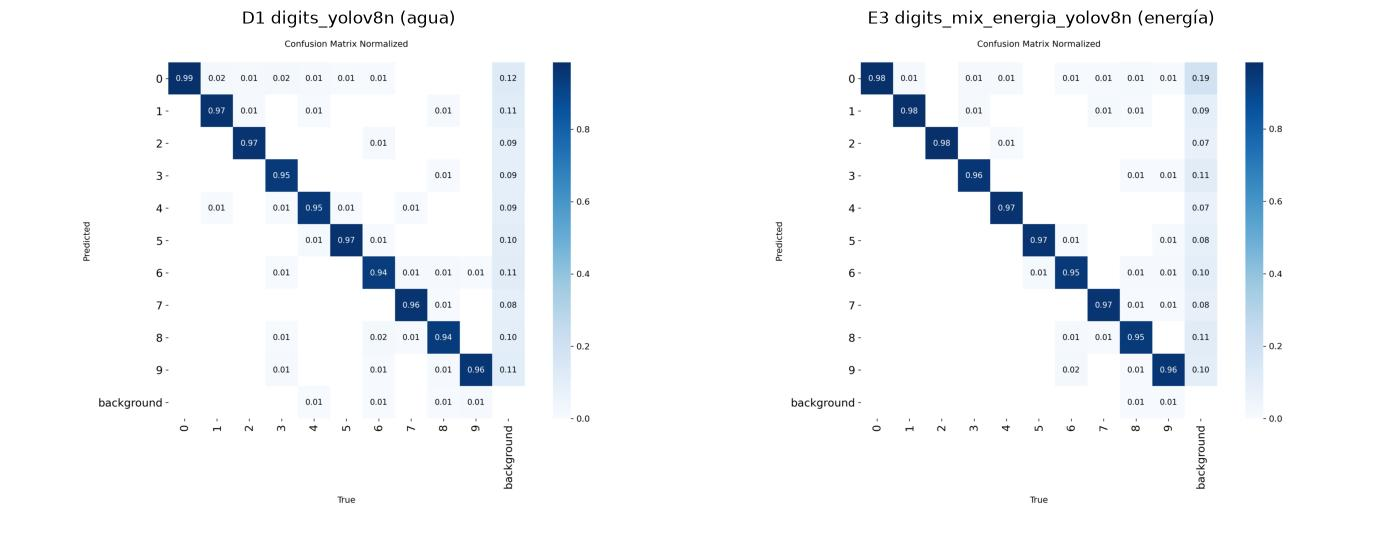

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, name) in zip(axes, {"D1 digits_yolov8n (agua)": "digits_yolov8n",
                                     "E3 digits_mix_energia_yolov8n (energía)": "digits_mix_energia_yolov8n"}.items()):
    ax.imshow(plt.imread(EXP / name / "confusion_matrix_normalized.png"))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

En el test empatan (mAP50-95 0,687 contra 0,694), pero en las fotos de campo YOLOv8n lee bastante mejor (71,2 % contra 61,4 % de lecturas exactas, sección 6): la métrica de detección en el dominio de entrenamiento no anticipó la diferencia en el dominio real. Se queda YOLOv8n. El 1 es el dígito más difícil en los dos: es angosto y una caja corrida lo pierde.

**Ronda D3–D9: más capacidad, más resolución, más aumentaciones y otra arquitectura.** Se probó si el detector de agua mejora con modelos YOLO más grandes (D3 YOLOv8s, D4 YOLOv8m), más resolución (D5 YOLOv8s a 640 px), más aumentaciones de color y geometría (D6) o un detector con transformer, RT-DETR-L: primero con la receta de entrenamiento de YOLO (D7) y después con la del RT-DETR original (D8: AdamW, `lr0` 1e-4, `weight_decay` 1e-4). Se elige con la validación pública, con una regla fijada de antemano: pasar a evaluar en CEML solo si se mejora a D1 en más de 0,01 de mAP50-95. La validación es el mejor mAP50-95 por época; la latencia es en la CPU de Kaggle (30 recortes del test). D9 prueba YOLO26n, la versión más reciente de Ultralytics; se entrenó en local (RTX 4070 Laptop) y su latencia se midió en otra CPU, por lo que no se ubica en el gráfico.


,val mAP50-95,test mAP50,test mAP50-95,latencia CPU (ms),pesos (MB)
modelo,,,,,
"D1 YOLOv8n, 416",0.709,0.983,0.687,NaN,6.5
"D6 YOLOv8n + aug, 416",0.705,0.985,0.682,40.4,6.5
"D3 YOLOv8s, 416",0.706,0.981,0.681,95.6,22.5
"D4 YOLOv8m, 416",0.706,0.985,0.684,220.2,52.0
"D5 YOLOv8s, 640",0.707,0.982,0.680,234.5,22.5
D7 RT-DETR-L (receta YOLO),0.576,0.974,0.571,479.6,66.2
D8 RT-DETR-L (AdamW),0.608,0.968,0.587,464.8,66.2
"D9 YOLO26n, 416",0.712,0.982,0.688,7.2,5.4


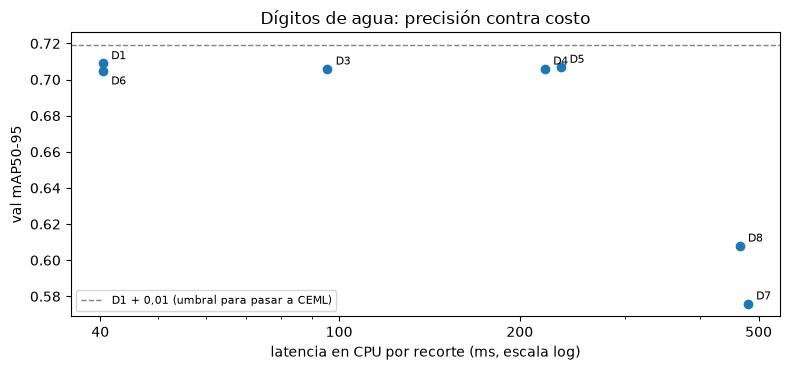

In [12]:
round_ = {"D1 YOLOv8n, 416": "digits_yolov8n", "D6 YOLOv8n + aug, 416": "digits_yolov8n_aug",
          "D3 YOLOv8s, 416": "digits_yolov8s", "D4 YOLOv8m, 416": "digits_yolov8m",
          "D5 YOLOv8s, 640": "digits_yolov8s_640", "D7 RT-DETR-L (receta YOLO)": "digits_rtdetr_l",
          "D8 RT-DETR-L (AdamW)": "digits_rtdetr_l_adamw",
          "D9 YOLO26n, 416": "digits_yolo26n"}
rows = []
for label, name in round_.items():
    e = load(f"{name}/eval.json")
    log = pd.read_csv(EXP / name / "results.csv")
    log.columns = log.columns.str.strip()
    rows.append({"modelo": label, "val mAP50-95": round(log["metrics/mAP50-95(B)"].max(), 3),
                 "test mAP50": e["test"]["map50"], "test mAP50-95": e["test"]["map50_95"],
                 "latencia CPU (ms)": e.get("latencia_cpu_ms"),
                 "pesos (MB)": round((ROOT / "models" / f"{name}.pt").stat().st_size / 1e6, 1)})
round_table = pd.DataFrame(rows).set_index("modelo")
display(round_table)

# D1 no se midió en la CPU de Kaggle: se ubica con la latencia de D6, que es la misma arquitectura.
points = round_table.copy()
points.loc["D1 YOLOv8n, 416", "latencia CPU (ms)"] = points.loc["D6 YOLOv8n + aug, 416", "latencia CPU (ms)"]
# D9 se midió en otra CPU (local): su latencia no es comparable con la de Kaggle, así que queda fuera del gráfico.
points = points.drop(index="D9 YOLO26n, 416")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(points["latencia CPU (ms)"], points["val mAP50-95"])
for label, r in points.iterrows():
    ax.annotate(label.split(" ")[0], (r["latencia CPU (ms)"], r["val mAP50-95"]), textcoords="offset points",
                xytext=(6, -10) if label.startswith("D6") else (6, 3), fontsize=8)
ax.axhline(round_table.loc["D1 YOLOv8n, 416", "val mAP50-95"] + 0.01, ls="--", lw=1, color="gray",
           label="D1 + 0,01 (umbral para pasar a CEML)")
ax.set(xscale="log", xticks=[40, 100, 200, 500], xticklabels=["40", "100", "200", "500"], xlabel="latencia en CPU por recorte (ms, escala log)", ylabel="val mAP50-95",
       title="Dígitos de agua: precisión contra costo")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()


- **Ninguna variante pasa el umbral.** Las YOLO más grandes, a más resolución o con más aumentaciones empatan con D1 en validación (0,705 a 0,709): hay un techo común, probablemente por el ruido de las etiquetas más que por la capacidad, y solo suman latencia (hasta unas 6 veces) y peso (hasta 8 veces).
- **El transformer queda abajo aun con su receta.** RT-DETR-L detecta casi igual (mAP50 de test ~0,97 contra 0,983) pero ajusta peor las cajas: con la receta de YOLO queda en 0,576 de validación, y con la del RT-DETR original sube a 0,608, todavía 0,10 por debajo de D1. Es unas 12 veces más lento en CPU y pesa 10 veces más. Lo único que no se replicó es la tasa más baja del backbone (1e-5 en el original), que Ultralytics no expone.
- **La versión más reciente tampoco.** YOLO26n (D9, sin NMS y con menos parámetros) queda en 0,712 contra 0,709 de D1: el mismo techo que D3–D6. Es algo más liviano y rápido, pero no lee mejor los dígitos.
- Ningún modelo pasó a CEML, así que el detector de la entrega sigue siendo YOLOv8n (D1).


### Energía

El detector de agua nunca vio un LCD de 7 segmentos ni los rodillos de los medidores de energía. Se probaron tres detectores, todos YOLOv8n con los mismos hiperparámetros:

- **E1 `digits_mix_yolov8n`**: water-meter-dataset más dos datasets públicos de dígitos LCD (meter-digits-5srka y meter-digits-frvqn, CC BY 4.0).
- **E3 `digits_mix_energia_yolov8n`**: E1 más 483 visores de energía CEML rectificados. Las cajas se pre-etiquetaron con el detector de agua, se corrigieron en Roboflow y se revisaron contra el modelo. No incluye ninguna foto de los medidores de la muestra; el split train/val es por medidor.
- **E4 `digits_mix_energia_rev_yolov8n`**: igual que E3, pero solo con los 209 recortes que la revisión dio por legibles (menos datos, más limpios).

Primero, el test público (el mismo para los tres, sin energía CEML):

In [13]:
detectors = {"E1 digits_mix": ("digits_mix_yolov8n", 0),
             "E3 + energía (todos)": ("digits_mix_energia_yolov8n", 483),
             "E4 + energía (solo legibles)": ("digits_mix_energia_rev_yolov8n", 209)}
pd.DataFrame([{"detector": name, "recortes de energía": n, **load(f"{exp}/eval.json")["test"]}
              for name, (exp, n) in detectors.items()]).set_index("detector")

,recortes de energía,map50,map50_95,precision,recall
detector,,,,,
E1 digits_mix,0,0.985,0.712,0.969,0.967
E3 + energía (todos),483,0.985,0.713,0.964,0.967
E4 + energía (solo legibles),209,0.986,0.713,0.967,0.965


En el test público los tres dan lo mismo: sumar energía no hace perder nada en agua ni en los LCD públicos, pero tampoco dice cuál lee mejor energía. Para eso se leen las 201 fotos de la muestra con cada detector, con el resto del pipeline de energía fijo (segmentador de energía, sin giro, clasificador de formato con su predicción out-of-fold). La segmentación se hace una sola vez, así las tres variantes leen sobre el mismo visor.

In [14]:
energy_segment, _ = load_models("models/toloka_yfzw4_energia_yolov8n_seg.pt", "models/digits_mix_energia_yolov8n.pt",
                                device="cpu")
energy_polygons = segment_all(energy_truth, ENERGY / "images", energy_segment)
energy_oof = load_oof("meter_layout_agua_energia")

energy_reads = {}
for name, (exp, _) in detectors.items():
    _, detect = load_models("models/toloka_yfzw4_energia_yolov8n_seg.pt", f"models/{exp}.pt", device="cpu")
    energy_reads[name] = read_all(energy_truth, ENERGY / "images", energy_polygons, detect, energy_oof,
                                  allow_flip=False)
pd.DataFrame({name: score(energy_truth, preds) for name, preds in energy_reads.items()}).T[METRICS]

,exacta,m3_exactos,cer,sin_lectura
E1 digits_mix,0.323,0.463,0.174,0.0
E3 + energía (todos),0.667,0.791,0.082,0.0
E4 + energía (solo legibles),0.657,0.761,0.082,0.0


Acá sí aparece la diferencia: los visores de energía etiquetados duplican la lectura exacta (E1 contra E3). Entre E3 y E4 gana E3 por poco: más datos pesan más que el ruido de los recortes dudosos. La app usa E3 para energía y sigue con `digits_yolov8n` para agua, porque E3 lee peor agua (65,2 % contra 71,2 % de lecturas exactas en CEML).

## 4. Orientación (giro de 180°)

**El problema.** Después de rectificar, el visor queda horizontal, pero puede estar al revés. Los medidores de agua están en el piso, dentro de una caja, y se pueden fotografiar desde cualquier lado.

**Agua.** El pipeline lee el visor en las dos orientaciones y se queda con una: si solo una muestra los dígitos rojos (la fracción) a la derecha, es esa; si el color no decide, gana la de mayor confianza del detector.

**Energía.** No hay fracción roja que decida, y los dígitos de 7 segmentos girados 180° siguen pareciendo dígitos (un 6 girado es un 9, un 2 es un 2), así que la confianza no distingue bien. Pero los medidores de energía están en pared o pilar y se fotografían siempre derechos. Por eso se leen tal como quedaron, sin probar el giro (`read_meter(..., allow_flip=False)`).

La tabla compara las dos reglas en cada servicio, con los modelos finales de cada uno (agua también se segmenta acá; tarda un minuto).

In [15]:
water_segment, water_detect = load_models("models/toloka_yfzw4_yolov8n_seg.pt", "models/digits_yolov8n.pt",
                                          device="cpu")
water_polygons = segment_all(water_truth, WATER / "images", water_segment)
water_oof = load_oof("meter_layout_mnv3s")
_, energy_detect = load_models("models/toloka_yfzw4_energia_yolov8n_seg.pt",
                               "models/digits_mix_energia_yolov8n.pt", device="cpu")

water_reads = read_all(water_truth, WATER / "images", water_polygons, water_detect, water_oof, allow_flip=True)
energy_flip_reads = read_all(energy_truth, ENERGY / "images", energy_polygons, energy_detect, energy_oof,
                             allow_flip=True)
orientation = {
    ("agua", "probando el giro"): score(water_truth, water_reads),
    ("agua", "sin giro"): score(water_truth, read_all(water_truth, WATER / "images", water_polygons,
                                                      water_detect, water_oof, allow_flip=False)),
    ("energía", "probando el giro"): score(energy_truth, energy_flip_reads),
    ("energía", "sin giro"): score(energy_truth, energy_reads["E3 + energía (todos)"]),
}
pd.DataFrame(orientation).T[METRICS]

exacta  m3_exactos    cer  sin_lectura
agua    probando el giro   0.712       0.780  0.121        0.081
        sin giro           0.706       0.771  0.132        0.081
energía probando el giro   0.587       0.692  0.182        0.000
        sin giro           0.667       0.791  0.082        0.000

- **Agua**: probar el giro gana poco (71,2 % contra 70,6 %): en estas fotos son pocos los visores que quedan al revés, y para esos el color de la fracción decide bien. Se mantiene porque no cuesta lectura y cubre las fotos tomadas desde el otro lado.
- **Energía**: probar el giro resta 8 puntos de lectura exacta (58,7 % contra 66,7 %) y duplica el CER: da vuelta lecturas que estaban bien, porque la confianza del detector no alcanza para decidir.

Por eso la orientación se decide por servicio, y la app la toma del medidor que se está leyendo.

Abajo, fotos de energía que sin giro se leen bien y que, al probar el giro, el pipeline da vuelta: el visor tal como está y girado 180°, con lo que lee el detector en cada uno. Al revés, en los rodillos un 9 se lee 6 y un 7 se lee 1, y un 000972 de LCD se lee 26000: la lectura girada tiene sentido y a veces más confianza que la correcta.

Lecturas de energía que el giro arruina: 16 de 201


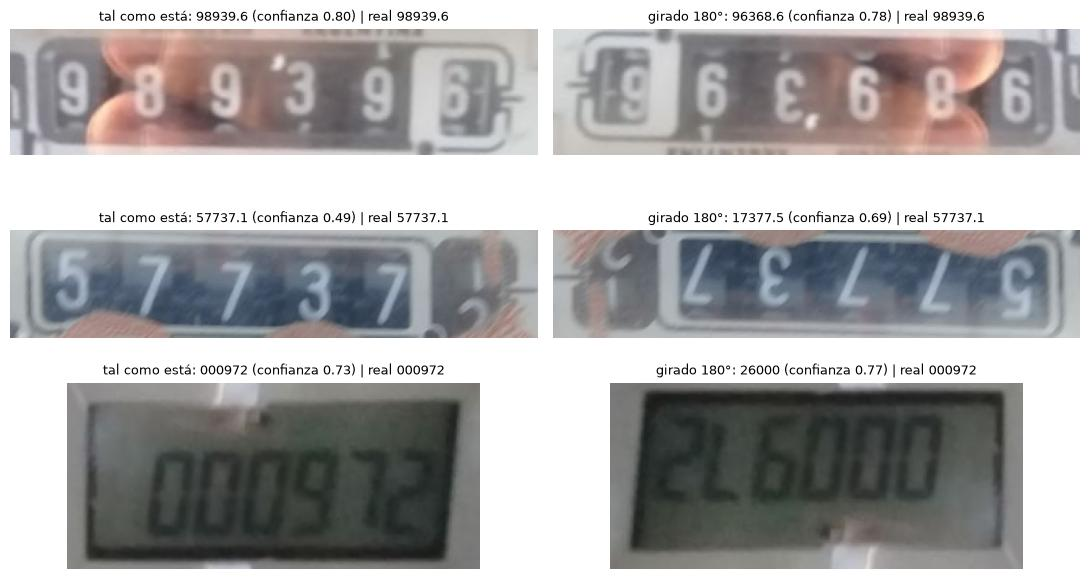

In [16]:
energy_truth_by_file = {t["file"]: t["reading"] for t in energy_truth}
energy_upright = energy_reads["E3 + energía (todos)"]
turned_wrong = [f for f in energy_truth_by_file
                if (energy_upright[f] or ("",))[0] == energy_truth_by_file[f]
                and (energy_flip_reads[f] or ("",))[0] != energy_truth_by_file[f]]
print(f"Lecturas de energía que el giro arruina: {len(turned_wrong)} de {len(energy_truth)}")

fig, grid = plt.subplots(3, 2, figsize=(11, 6))
for file, axes in zip(turned_wrong[:3], grid):
    image = cv2.imread(str(ENERGY / "images" / file))
    label = energy_oof.get(file, ("", 0.0))
    for ax, allow_flip in zip(axes, (False, True)):
        result = read_meter(image, lambda _img: energy_polygons[file], energy_detect, lambda _input: label,
                            allow_flip=allow_flip)
        ax.imshow(cv2.cvtColor(result.crop, cv2.COLOR_BGR2RGB))
        state = "girado 180°" if result.flipped else "tal como está"
        ax.set_title(f"{state}: {result.reading.formatted} (confianza {result.reading.confidence:.2f}) | "
                     f"real {energy_truth_by_file[file]}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Formato del medidor (m³ y fracción)

**El problema.** Los dígitos solos no dicen dónde va el punto. Cada modelo de medidor tiene una cantidad fija de dígitos de unidades (m³ en agua, kWh en energía, lo que se factura) y de fracción, y se nombra `<unidades>_<fracción>`: `5_2` son cinco de m³ y dos de fracción. Un punto mal puesto cambia por 10 o por 100 lo facturado.

**La solución.** Una CNN (MobileNetV3-small preentrenada en ImageNet, transfer learning) clasifica el formato a partir del visor con su entorno (logo, marco, forma de la tapa), que es lo que identifica al modelo a simple vista. Con su formato, el pipeline pone el punto. Si el clasificador duda (probabilidad menor a 0,5), decide el color: en agua la fracción va en rojo.

**Evaluación.** Validación cruzada estratificada de 5 folds: cada foto se predice con un modelo que no la vio. Esas predicciones out-of-fold son también las que se usan en la lectura de punta a punta, así ninguna foto se evalúa con un clasificador que la haya visto.

### Agua

Fotos: 320 | exactitud: 98.4% | F1 macro: 0.954


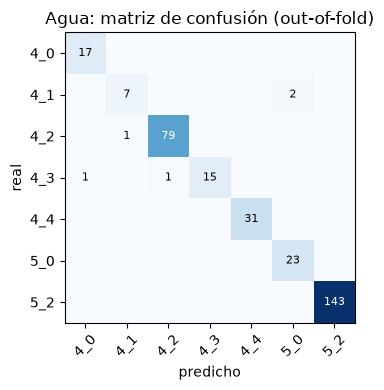

In [17]:
def plot_confusion(cv, ax, title):
    ax.imshow(cv["confusion"], cmap="Blues")
    ax.set_xticks(range(len(cv["classes"])), cv["classes"], rotation=45)
    ax.set_yticks(range(len(cv["classes"])), cv["classes"])
    top = max(max(row) for row in cv["confusion"])
    for i, row in enumerate(cv["confusion"]):
        for j, n in enumerate(row):
            if n:
                ax.text(j, i, n, ha="center", va="center", fontsize=8, color="white" if n > top / 2 else "black")
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title)


cv = load("meter_layout_mnv3s/cv.json")
print(f"Fotos: {cv['images']} | exactitud: {cv['accuracy']:.1%} | F1 macro: {cv['macro_f1']:.3f}")
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_confusion(cv, ax, "Agua: matriz de confusión (out-of-fold)")
plt.tight_layout()

El clasificador acierta el formato en el 98,4 % de las fotos, contra 70,8 % del color solo: el color falla con humedad, reflejos o fracciones blancas.

### Energía

Se entrenó un solo clasificador con agua y energía juntos (`meter_layout_agua_energia`, 1107 fotos y 10 formatos), con los visores de energía revisados. Los formatos de energía son otros (`5_1`, `6_1`, `6_0`), y en energía el color no sirve de respaldo: la fracción no va en rojo.

Fotos: 1107 | exactitud: 99.4% | F1 macro: 0.967


,4_0,4_1,4_2,4_3,4_4,5_0,5_1,5_2,6_0,6_1
F1,0.971,0.875,0.982,0.867,1.0,0.979,0.998,1.0,1.0,0.998


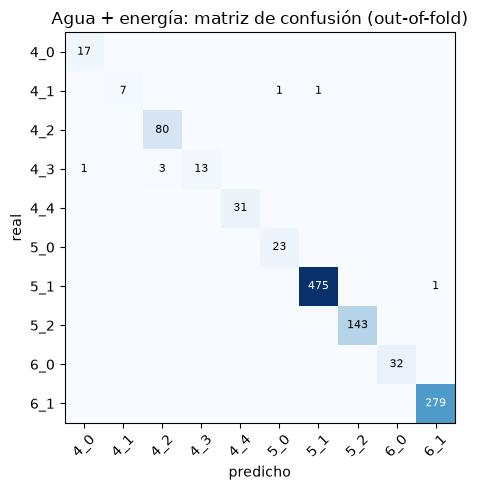

In [18]:
cv_mix = load("meter_layout_agua_energia/cv.json")
print(f"Fotos: {cv_mix['images']} | exactitud: {cv_mix['accuracy']:.1%} | F1 macro: {cv_mix['macro_f1']:.3f}")
display(pd.Series(cv_mix["per_class_f1"], name="F1").to_frame().T)
fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion(cv_mix, ax, "Agua + energía: matriz de confusión (out-of-fold)")
plt.tight_layout()

**Los errores del clasificador** (predicción out-of-fold distinta del formato anotado), con la entrada que ve: el visor con su entorno.

Errores: 7 de 1107 fotos


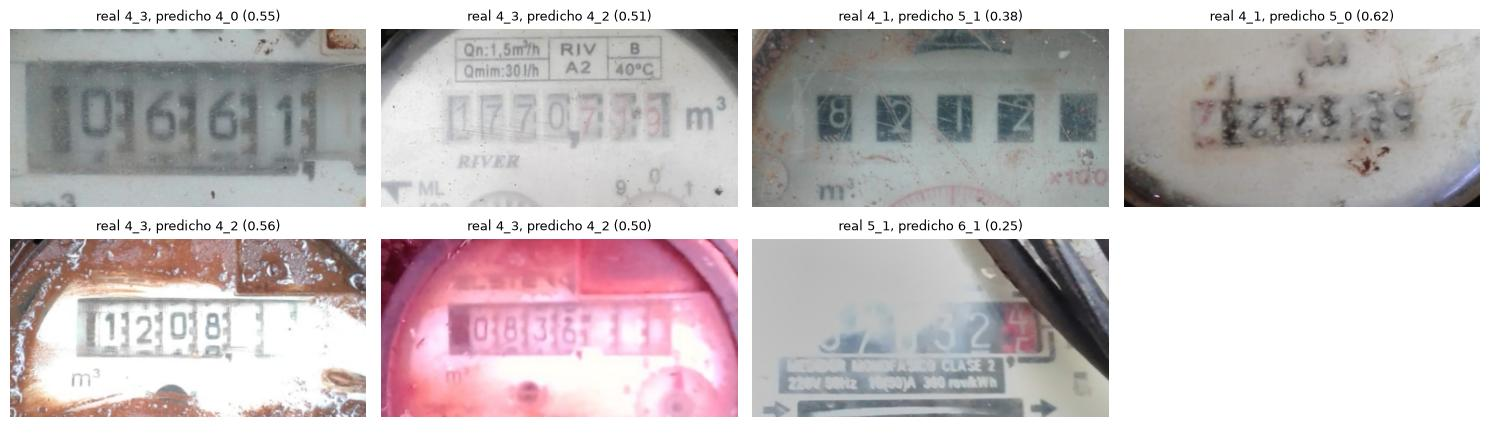

In [19]:
from meter_reader.layout import model_input

oof_rows = pd.read_csv(EXP / "meter_layout_agua_energia/oof.csv", dtype=str)
errors = oof_rows[oof_rows["real"] != oof_rows["predicho"]]
print(f"Errores: {len(errors)} de {len(oof_rows)} fotos")
fig, axes = plt.subplots(2, 4, figsize=(15, 4.5))
for ax in axes.flat:
    ax.axis("off")
for ax, r in zip(axes.flat, errors.itertuples()):
    root = ENERGY if r.file.startswith("energia_") else WATER
    image = cv2.imread(str(root / "images" / r.file))
    polygon = yolo_polygon(root / "labels" / f"{Path(r.file).stem}.txt", image.shape[1], image.shape[0])
    ax.imshow(cv2.cvtColor(model_input(image, polygon.astype(np.float32)), cv2.COLOR_BGR2RGB))
    ax.set_title(f"real {r.real}, predicho {r.predicho} ({float(r.probabilidad):.2f})", fontsize=9)
plt.tight_layout()
plt.show()

Juntar los dos servicios no confunde al clasificador: la exactitud sube a 99,4 %, porque los formatos de energía (`5_1`, `6_1`) tienen muchas fotos y se distinguen bien. Los errores que quedan están en formatos de agua con pocas fotos (`4_1`, `4_3`). Agua sigue usando `meter_layout_mnv3s`, el modelo de la entrega.

## 6. Lectura de punta a punta

`scripts/evaluate_pipeline.py` lee todas las fotos de prueba y compara la lectura con la anotada a mano. Todas las configuraciones usan la misma segmentación del visor.

- **Exacta**: la lectura completa coincide, con el punto y los ceros a la izquierda (sobre las fotos con la fracción legible).
- **m³ exactos**: coincide la parte entera, que es lo que se factura (kWh en energía; el nombre de la columna es el de agua).
- **CER**: errores de edición entre dígitos predichos y reales, sobre la cantidad de dígitos reales.
- **Sin lectura**: no se encontró el visor o ningún dígito.
- **Sin revisión (cobertura)**: lecturas con confianza ≥ 0,5, que la app acepta sin marcarlas para revisar; **exacta sin revisión** es cuántas de ellas son exactas.

Configuraciones:

- **A**: rectificado + YOLOv8n + clasificador de formato (el pipeline final).
- **B**: como A pero el punto lo decide solo el color.
- **C**: como A pero con recorte por caja en lugar de rectificado. **A contra C es el experimento principal.**
- **D**: como A con YOLO11n (el de agua) en lugar de YOLOv8n.
- **E**: OCR genérico (EasyOCR) sobre el mismo recorte que A: la línea de base.

In [20]:
def results_table(path):
    results = load(path)
    latency = results.pop("latencia_cpu_ms")
    table = pd.DataFrame(results).T.set_index("configuracion")
    table.index = [f"{key}. {name}" for key, name in zip(results, table.index)]
    return table[METRICS + ["cobertura_confianza", "exacta_con_confianza"]].astype(float), latency


def plot_results(table, title):
    ax = table[["exacta", "m3_exactos"]].plot.barh(figsize=(8, 3.5), xlim=(0, 1))
    ax.invert_yaxis()
    ax.set_xlabel("proporción de fotos")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

### Agua

323 fotos CEML verificadas y legibles (316 con la fracción legible). Resultados en `experiments/pipeline_ceml/`.

,exacta,m3_exactos,cer,sin_lectura,cobertura_confianza,exacta_con_confianza
A. rectificado + YOLOv8n + clasificador,0.712,0.780,0.121,0.081,0.807,0.831
B. rectificado + YOLOv8n + color,0.547,0.582,0.121,0.081,0.807,0.631
C. caja + YOLOv8n + clasificador,0.636,0.718,0.176,0.124,0.737,0.828
D. rectificado + YOLO11n + clasificador,0.614,0.734,0.151,0.081,0.810,0.742
E. rectificado + EasyOCR + clasificador,0.003,0.006,0.898,0.164,0.076,0.042


Latencia del pipeline final (A) en CPU: 73.9 ms por foto


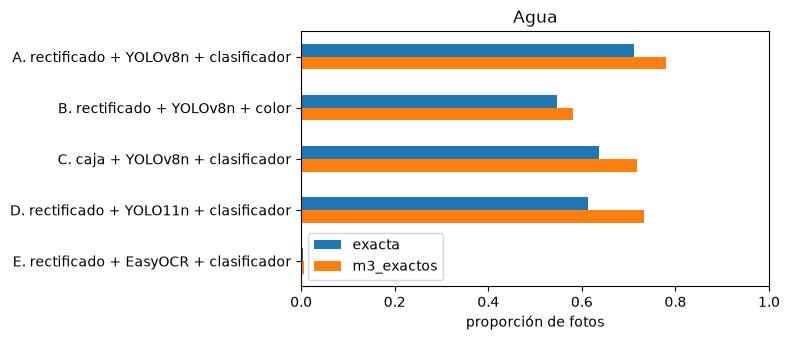

In [21]:
water_table, water_latency = results_table("pipeline_ceml/results.json")
display(water_table)
print(f"Latencia del pipeline final (A) en CPU: {water_latency} ms por foto")
plot_results(water_table, "Agua")

- **Rectificar sirve (A contra C)**: +7,6 puntos de lectura exacta y +6,2 de m³; el CER baja de 0,176 a 0,121 y las fotos sin lectura de 12,4 % a 8,0 %.
- **El clasificador de formato (A contra B)**: +16,5 puntos de lectura exacta con los mismos dígitos (el CER es idéntico): todo lo que cambia es dónde va el punto.
- **YOLOv8n sobre YOLO11n (A contra D)**: 71,2 % contra 61,4 %, aunque empataban en el test de dígitos.
- **EasyOCR no sirve para rodillos (E)**: lee las barras entre rodillos y los números a medio girar.
- **La confianza como filtro**: el 80,7 % de las lecturas pasa sin revisión y de esas el 83 % es exacta; el resto va a revisión manual en la app.

**Exactitud por formato de medidor** (configuración A), cruzando las predicciones con el formato anotado en `data/ceml/readings.csv`:

In [22]:
def by_group(predictions_csv, sheet, column):
    preds = pd.read_csv(EXP / predictions_csv, dtype=str).fillna("")
    df = preds.merge(sheet[["file", "modelo", *([column] if column != "formato" else [])]], on="file")
    df["formato"] = df["modelo"].str.extract(r"_(\d_\d)$")[0].fillna("sin modelo")
    df = df[~df["reading"].str.endswith(".")]  # fracción ilegible: no cuenta para la lectura exacta
    df["exacta"] = df["A"] == df["reading"]
    return df, df.groupby(column)["exacta"].agg(fotos="size", exacta="mean").sort_values("fotos", ascending=False)


water_sheet = pd.read_csv(WATER / "readings.csv", dtype=str).fillna("")
water_df, table = by_group("pipeline_ceml/predictions.csv", water_sheet, "formato")
table

,fotos,exacta
formato,,
5_2,142,0.852
4_2,79,0.734
4_4,31,0.484
5_0,23,0.522
4_0,17,0.588
4_3,11,0.545
4_1,9,0.333
5_3,2,0.000
sin modelo,2,0.000


Los formatos con más fotos (`5_2`, `4_2`) se leen mejor que los que tienen pocas (`4_4`, `5_0`, `4_1`).

### Energía

Las 201 fotos de la muestra de energía (101 de rodillos y 100 LCD), con el pipeline de energía: segmentador con energía, E3, clasificador de agua y energía, sin giro. D usa el YOLO11n de agua, que no vio energía, así que no es comparable con A. Resultados en `experiments/pipeline_ceml_energia/`.

,exacta,m3_exactos,cer,sin_lectura,cobertura_confianza,exacta_con_confianza
A. rectificado + YOLOv8n + clasificador,0.667,0.791,0.082,0.000,0.881,0.740
B. rectificado + YOLOv8n + color,0.030,0.055,0.082,0.000,0.881,0.034
C. caja + YOLOv8n + clasificador,0.517,0.622,0.226,0.050,0.667,0.709
D. rectificado + YOLO11n + clasificador,0.219,0.348,0.446,0.035,0.368,0.527
E. rectificado + EasyOCR + clasificador,0.030,0.085,0.577,0.119,0.303,0.098


Latencia del pipeline final (A) en CPU: 60.6 ms por foto (una sola orientación)


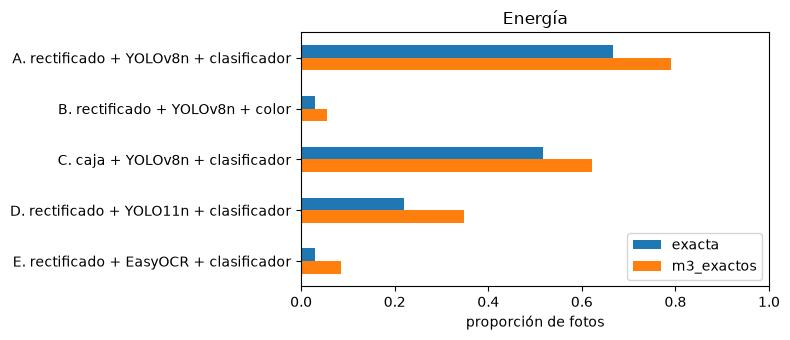

In [23]:
energy_table, energy_latency = results_table("pipeline_ceml_energia/results.json")
display(energy_table)
print(f"Latencia del pipeline final (A) en CPU: {energy_latency} ms por foto (una sola orientación)")
plot_results(energy_table, "Energía")

- **Rectificar también sirve en energía (A contra C)**: +15,0 puntos de lectura exacta, el doble que en agua, y el recorte por caja deja un 5 % de fotos sin lectura.
- **Sin el clasificador no hay punto (A contra B)**: el color no ubica la fracción porque no es roja, y la lectura exacta cae a 3 %.
- **La confianza como filtro**: el 88,1 % de las lecturas pasa sin revisión, pero de esas es exacta el 74 % (83 % en agua): en energía conviene un umbral más alto.
- **El camino**: con el pipeline de agua, energía leía 18,9 % exacto. Segmentador con energía: 16,9 % (pero las fotos sin lectura bajan de 22,9 % a 0 %). Sin giro: 27,4 %. Clasificador reentrenado: 32,3 %. Dígitos de energía (E3): 66,7 %.

**Exactitud por tipo de medidor y por formato** (configuración A):

In [24]:
energy_df, by_type = by_group("pipeline_ceml_energia/predictions.csv", energy_sheet, "tipo")
display(by_type)
energy_df.groupby("formato")["exacta"].agg(fotos="size", exacta="mean").sort_values("fotos", ascending=False)

,fotos,exacta
tipo,,
rodillos,101,0.574
lcd,100,0.760


,fotos,exacta
formato,,
5_1,109,0.578
6_1,79,0.785
6_0,12,0.750
sin modelo,1,0.000


Los LCD se leen mejor que los rodillos; los rodillos de energía son lo que más queda por mejorar.

### Dónde ayuda rectificar: exactitud según la inclinación del visor

El análisis exploratorio mostró que la mayoría de los visores están casi horizontales, así que el efecto de rectificar se diluye en el promedio. Separando las fotos por la inclinación del visor segmentado:

fotos  A rectificado  C recorte por caja
servicio inclinación                                          
agua     > 15°         21.0          0.619               0.000
         ≤ 15°        270.0          0.785               0.744
energía  > 15°         32.0          0.750               0.000
         ≤ 15°        169.0          0.651               0.615

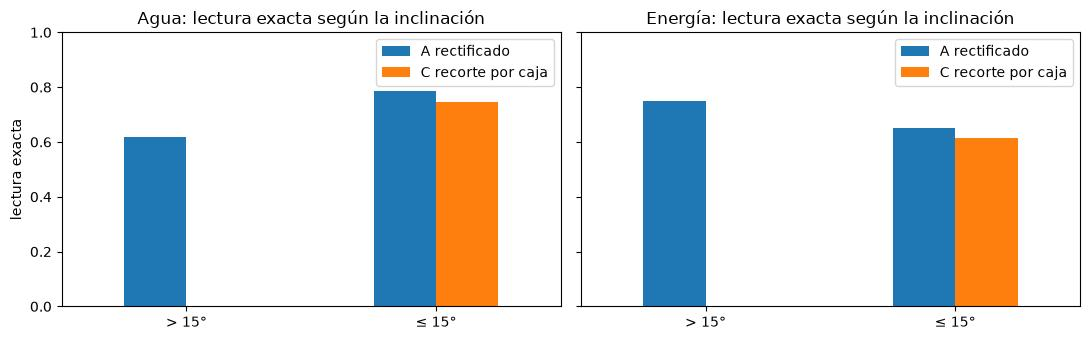

In [25]:
def by_tilt(predictions_csv, polygons):
    preds = pd.read_csv(EXP / predictions_csv, dtype=str).fillna("")
    preds = preds[~preds["reading"].str.endswith(".")]
    preds["inclinación"] = [("sin visor" if polygons[f] is None or len(polygons[f]) < 3
                             else "> 15°" if tilt(polygons[f]) > 15 else "≤ 15°") for f in preds["file"]]
    preds = preds[preds["inclinación"] != "sin visor"]
    table = preds.groupby("inclinación").apply(
        lambda g: pd.Series({"fotos": len(g), "A rectificado": (g["A"] == g["reading"]).mean(),
                             "C recorte por caja": (g["C"] == g["reading"]).mean()}), include_groups=False)
    return table


tilt_tables = {"agua": by_tilt("pipeline_ceml/predictions.csv", water_polygons),
               "energía": by_tilt("pipeline_ceml_energia/predictions.csv", energy_polygons)}
display(pd.concat(tilt_tables, names=["servicio"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (service, table) in zip(axes, tilt_tables.items()):
    table[["A rectificado", "C recorte por caja"]].plot.bar(ax=ax, rot=0, ylim=(0, 1))
    ax.set(title=f"{service.capitalize()}: lectura exacta según la inclinación", xlabel="", ylabel="lectura exacta")
plt.tight_layout()
plt.show()

- **Con el visor casi horizontal (≤ 15°)** rectificar suma poco: 78,5 % contra 74,4 % en agua y 65,1 % contra 61,5 % en energía.
- **Con el visor inclinado (> 15°)** el recorte por caja no lee ninguna foto, en ninguno de los dos servicios; rectificando se leen el 61,9 % en agua y el 75,0 % en energía. Son pocas fotos (21 y 32), pero la diferencia es total: el detector se entrenó con visores horizontales y un recorte torcido no le sirve.
- Confirma lo que anticipaba el análisis exploratorio: la mejora promedio de rectificar (+7,6 puntos en agua y +15,0 en energía) sale casi toda de la minoría de visores inclinados. En energía pesa más porque hay más (16 % de las fotos contra 7 % en agua).

### La confianza como filtro: cobertura contra exactitud

La app acepta sin revisión las lecturas con confianza mayor o igual a un umbral (0,5) y manda las demás a revisión manual. Subir el umbral deja pasar menos lecturas (cobertura) pero más exactas. La curva muestra ese compromiso para cada servicio, con el pipeline final.

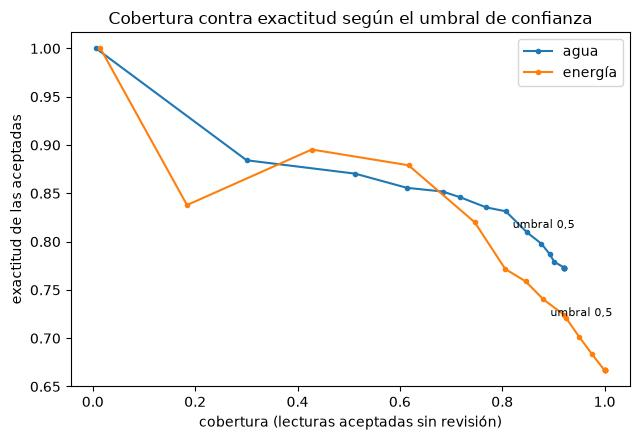

In [26]:
def coverage_curve(truth, predictions):
    full = [t for t in truth if t["fraction_known"]]
    rows = []
    for threshold in np.arange(0, 0.96, 0.05):
        passed = [t for t in full if predictions.get(t["file"]) and predictions[t["file"]][1] >= threshold]
        exact = sum(predictions[t["file"]][0] == t["reading"] for t in passed)
        rows.append({"umbral": threshold, "cobertura": len(passed) / len(full),
                     "exacta": exact / len(passed) if passed else np.nan})
    return pd.DataFrame(rows)


fig, ax = plt.subplots(figsize=(6.5, 4.5))
for service, truth, preds in (("agua", water_truth, water_reads),
                              ("energía", energy_truth, energy_reads["E3 + energía (todos)"])):
    curve = coverage_curve(truth, preds)
    ax.plot(curve["cobertura"], curve["exacta"], marker=".", label=service)
    at = curve.iloc[(curve["umbral"] - 0.5).abs().argmin()]
    ax.annotate("umbral 0,5", (at["cobertura"], at["exacta"]), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set(xlabel="cobertura (lecturas aceptadas sin revisión)", ylabel="exactitud de las aceptadas",
       title="Cobertura contra exactitud según el umbral de confianza")
ax.legend()
plt.tight_layout()
plt.show()

Cada punto es un umbral (de 0 a 0,95); a la izquierda las curvas saltan porque quedan pocas lecturas. Con el umbral de 0,5, agua acepta algo más del 80 % de las lecturas, con una exactitud cercana al 81 %; energía acepta cerca del 90 %, pero con una exactitud del 73 %. Para que lo aceptado en energía sea tan confiable como en agua, la cobertura tiene que bajar a cerca del 75 %: el umbral de energía tendría que ser más alto que el de agua.

### Qué tipo de errores quedan

Cada lectura que no es exacta se clasifica según la diferencia con la real: **sin lectura** (no se encontró el visor o ningún dígito), **punto mal puesto** (los dígitos coinciden pero no el punto), **dígitos de más o de menos** y **dígito confundido** (misma cantidad, alguno distinto).

,agua,energía
dígito confundido,0.133,0.214
dígitos de más o de menos,0.063,0.114
punto mal puesto,0.013,0.005
sin lectura,0.079,0.000


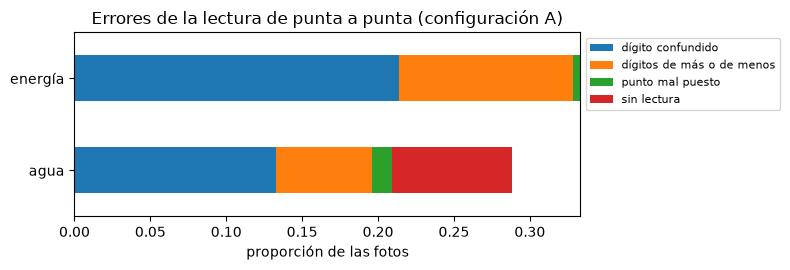

In [27]:
def error_type(predicted, real):
    if not predicted:
        return "sin lectura"
    digits_p, digits_r = predicted.replace(".", ""), real.replace(".", "")
    if digits_p == digits_r:
        return "punto mal puesto"
    if len(digits_p) != len(digits_r):
        return "dígitos de más o de menos"
    return "dígito confundido"


error_counts = {}
for service, csv_path in (("agua", "pipeline_ceml/predictions.csv"), ("energía", "pipeline_ceml_energia/predictions.csv")):
    preds = pd.read_csv(EXP / csv_path, dtype=str).fillna("")
    preds = preds[~preds["reading"].str.endswith(".")]
    wrong = preds[preds["A"] != preds["reading"]]
    error_counts[service] = wrong.apply(lambda r: error_type(r["A"], r["reading"]), axis=1).value_counts() / len(preds)
errors_table = pd.DataFrame(error_counts).fillna(0)
display(errors_table)
ax = errors_table.T.plot.barh(stacked=True, figsize=(8, 2.8))
ax.set(xlabel="proporción de las fotos", title="Errores de la lectura de punta a punta (configuración A)")
ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- **El error más común es un dígito confundido** (13,3 % de las fotos en agua y 21,4 % en energía): el visor se encontró y se contaron bien los dígitos, pero alguno se leyó mal.
- **Dígitos de más o de menos** (6,3 % y 11,4 %): una detección de más o un dígito que no se detectó.
- **El punto casi nunca queda mal** (1,3 % y 0,5 %): el clasificador de formato resuelve bien dónde va.
- **Sin lectura** solo en agua (7,9 %): fotos donde no se encontró el visor; en energía el segmentador los encuentra todos.

Lo que más queda por mejorar, en los dos servicios, es el detector de dígitos.

## 7. El pipeline paso a paso

Corre el pipeline final de cada servicio sobre algunas fotos de prueba: la foto con el visor segmentado (contorno verde), el visor rectificado con los dígitos detectados y la lectura contra la verdad de campo. Se eligen al azar (semilla fija) tres aciertos y tres errores de la configuración A. El formato de cada foto sale de la predicción out-of-fold del clasificador, igual que en la evaluación.

In [28]:
def show(file, axes, images_dir, polygons, detect, oof, truth, allow_flip):
    image = cv2.imread(str(images_dir / file))
    label = oof.get(file, ("", 0.0))
    result = read_meter(image, lambda _img: polygons[file], detect, lambda _input: label, allow_flip=allow_flip)
    overlay = image.copy()
    if result.polygon is not None:
        cv2.polylines(overlay, [result.polygon.astype(np.int32)], True, (0, 255, 0), max(3, image.shape[1] // 150))
    axes[0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[0].set_title(file, fontsize=8)
    if result.crop is not None:
        crop = result.crop.copy()
        for d in result.reading.digits:
            cv2.rectangle(crop, (int(d.x1), int(d.y1)), (int(d.x2), int(d.y2)), (0, 255, 0), 2)
        axes[1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ok = "✓" if result.reading.formatted == truth[file] else "✗"
    turned = ", girado 180°" if result.flipped else ""
    axes[1].set_title(f"{ok} leído {result.reading.formatted or '—'} | real {truth[file]}\n"
                      f"formato {label[0] if label[1] >= MIN_MODEL_PROB else 'por color'}, "
                      f"confianza {result.reading.confidence:.2f}{turned}", fontsize=9)
    for ax in axes:
        ax.axis("off")


def step_by_step(df, title, **kwargs):
    rng = np.random.default_rng(0)
    hits, misses = df[df["exacta"]]["file"].to_numpy(), df[~df["exacta"]]["file"].to_numpy()
    sample = [*rng.choice(hits, 3, replace=False), *rng.choice(misses, 3, replace=False)]
    truth = dict(zip(df["file"], df["reading"]))
    fig, grid = plt.subplots(len(sample), 2, figsize=(10, 3 * len(sample)), gridspec_kw={"width_ratios": [1, 1.6]})
    for file, axes in zip(sample, grid):
        show(file, axes, truth=truth, **kwargs)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

### Agua

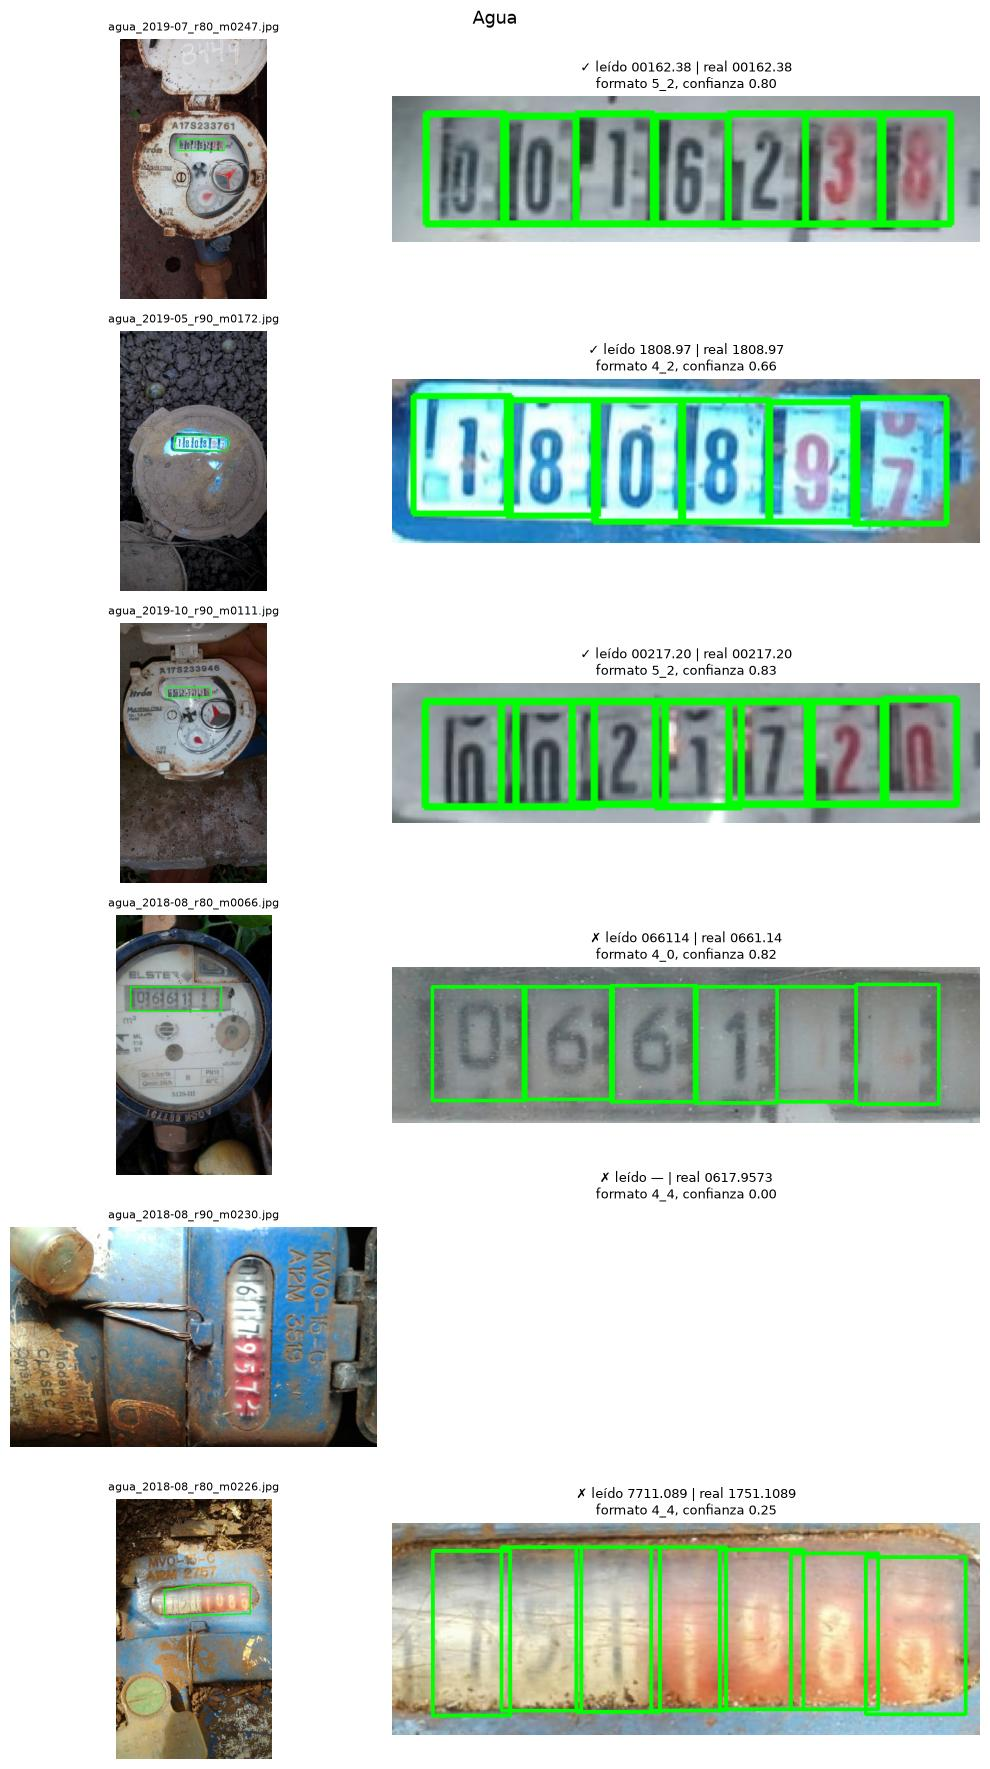

In [29]:
step_by_step(water_df, "Agua", images_dir=WATER / "images", polygons=water_polygons, detect=water_detect,
             oof=water_oof, allow_flip=True)

### Energía

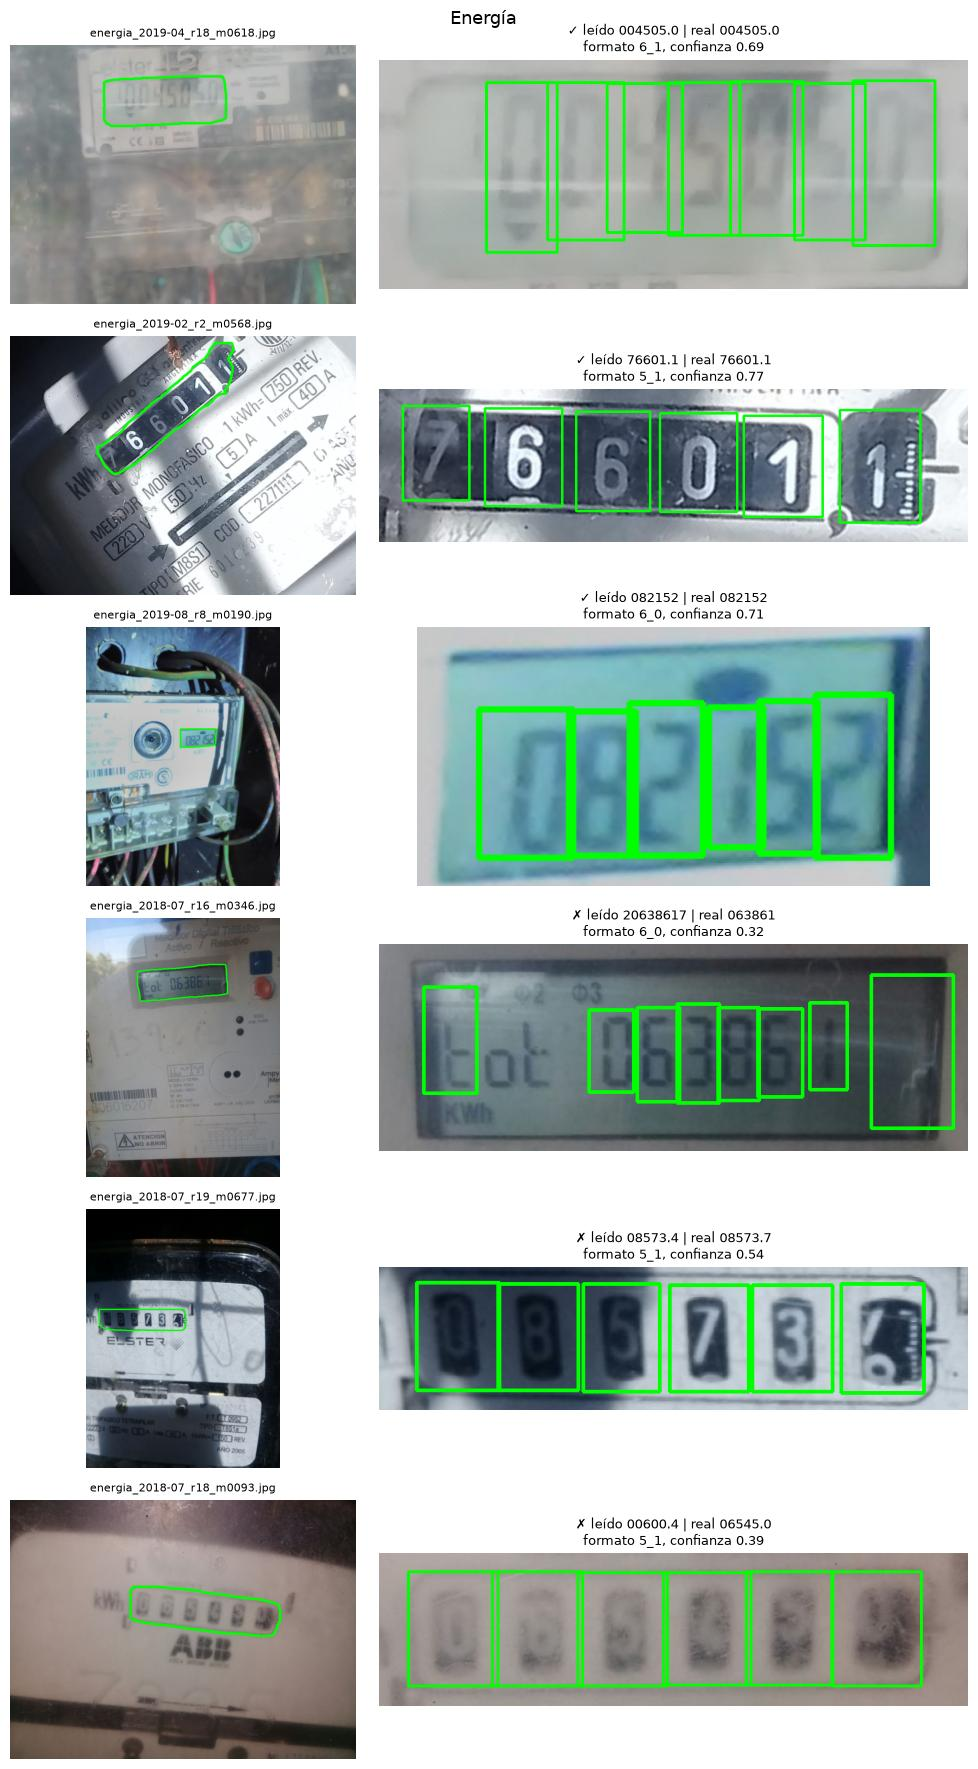

In [30]:
step_by_step(energy_df, "Energía", images_dir=ENERGY / "images", polygons=energy_polygons, detect=energy_detect,
             oof=energy_oof, allow_flip=False)

## 8. Conclusiones

**Del experimento principal**

- **Segmentar y rectificar el visor mejora la lectura** frente al recorte por caja en los dos servicios: +7,6 puntos de lectura exacta en agua y +15,0 en energía, con menor CER y menos fotos sin lectura.
- **La mejora está en los visores inclinados**: con más de 15° el recorte por caja no lee ninguna foto y rectificando se lee el 62 % (agua) y el 75 % (energía). Con el visor casi horizontal la diferencia es de 4 puntos.
- **Lo que más queda por mejorar es el detector de dígitos**: la mayoría de los errores son dígitos confundidos, de más o de menos; el punto casi nunca queda mal.

**De cada pieza**

- **Segmentación**: YOLOv8n-seg encuentra el visor mejor que Mask R-CNN en campo y es unas 20 veces más rápido en CPU. Para energía hizo falta etiquetar visores propios; con ellos la muestra pasa a leerse entera.
- **Dígitos**: la métrica en el test público no anticipa la lectura de campo (YOLOv8n contra YOLO11n en agua; E1, E3 y E4 en energía). Modelos más grandes, más resolución, más aumentaciones, un transformer (RT-DETR-L, aun con su propia receta) o la versión más reciente (YOLO26n) no mejoran a YOLOv8n en validación; los más grandes y el transformer cuestan entre 2 y 12 veces más en CPU. Lo que más mejoró energía fue etiquetar dígitos del propio dominio: de 32,3 % a 66,7 % de lecturas exactas.
- **Orientación**: probar el giro de 180° suma poco en agua (+0,6 puntos) y resta 8 en energía, donde los medidores están siempre derechos y los dígitos de 7 segmentos girados siguen pareciendo dígitos. Se decide por servicio.
- **Formato**: el clasificador de formato es lo que más aporta a lo facturado. En agua suma 16,5 puntos frente al color; en energía es imprescindible, porque la fracción no es roja.
- **Un OCR genérico no sirve** en ningún servicio (EasyOCR por debajo del 3 % de lecturas exactas).

**Para la app**

- Cada medidor tiene su servicio y se lee con los modelos de ese servicio: agua 71,2 % y energía 66,7 % de lecturas exactas, y 78,0 % y 79,1 % de m³ o kWh exactos.
- La confianza sirve de filtro: la mayoría de las lecturas se acepta sin revisión (80,7 % en agua, 88,1 % en energía) y las dudosas se mandan a revisión manual.